# **Comparación entre los modelos FHN-Basal y FHN-Cortisol**

## Inicialización de los modelos

In [ ]:
# ─── Importaciones generales ────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
import importlib # Recarga de módulos

In [64]:
# ─── Configuración LaTeX para Matplotlib ─────────────────────
from FHN_comparacion_Definicion import configurar_latex

usar_latex=True

# True:  Utiliza una instalación de LaTeX externa.
# False: Utiliza el motor interno de Matplotlib, mathtext.
configurar_latex(usar_latex)

In [61]:
import FHN_comparacion_Definicion
importlib.reload(FHN_comparacion_Definicion)
from FHN_comparacion_Definicion import (ComparadorFHN, CARPETA_IMAGENES)

comparador = ComparadorFHN()

In [54]:

# ──────────────────────────────────────────────────
#            Sistemas a comparar
# ──────────────────────────────────────────────────
I_comp = 0.5

# ── ── ── ── ── ── ── Clásico ── ── ── ── ── ── ── ── ── ──
#sistema_clasico = {
#    "nombre": "FHN clásico",
#    "a": 0.7,
#    "b": 0.8,
#    "epsilon": 0.08,
#    "I": I_comp
#}

# ── ── ── ── ── ── ──  Basal ── ── ── ── ── ── ── ── ── ──
a0, b0, epsilon0 = comparador.parametros_FHN_Barrett(GC=0.0)
sistema_basal = {
    "nombre": r"Basal",
    "a": a0,
    "b": b0,
    "epsilon": epsilon0,
    "I": I_comp
}

# ── ── ── ── ── ── ── ── 0.1 uM ── ── ── ── ── ── ── ── ── ──
a01, b01, epsilon01 = comparador.parametros_FHN_Barrett(GC=0.1)
sistema_GC01 = {
    "nombre": r"$\mathrm{C}=0.1\ \mu$M",
    "a": a01,
    "b": b01,
    "epsilon": epsilon01,
    "I": I_comp
}

# ── ── ── ── ── ── ── ── 1 uM ── ── ── ── ── ── ── ── ── ──
a1, b1, epsilon1 = comparador.parametros_FHN_Barrett(GC=1.0)
sistema_GC1 = {
    "nombre": r"$\mathrm{C}=1\ \mu$M",
    "a": a1,
    "b": b1,
    "epsilon": epsilon1,
    "I": I_comp
}

# ── ── ── ── ── ── ── ── 10 uM ── ── ── ── ── ── ── ── ── ──
a10, b10, epsilon10 = comparador.parametros_FHN_Barrett(GC=10.0)
sistema_GC10 = {
    "nombre": r"$\mathrm{C}=10\ \mu$M",
    "a": a10,
    "b": b10,
    "epsilon": epsilon10,
    "I": I_comp
}

sistemas = [
    sistema_basal,
    sistema_GC01,
    sistema_GC1,
    sistema_GC10
]
for sistema in sistemas:
    print(sistema["nombre"])
    print("a =", sistema["a"])
    print("b =", sistema["b"])
    print("epsilon =", sistema["epsilon"])
    print()

Basal
a = -0.61824408
b = 0.51584921
epsilon = 0.02865784

$\mathrm{C}=0.1\ \mu$M
a = -0.537867279752066
b = 0.4899174815702479
epsilon = 0.030179350743801653

$\mathrm{C}=1\ \mu$M
a = -0.21012144999999996
b = 0.38385835499999993
epsilon = 0.040505229999999996

$\mathrm{C}=10\ \mu$M
a = 0.06207020842975208
b = 0.2951997488429752
epsilon = 0.05652415074380165



## **Comparación de las ceroclinas de $V$ y $w$**

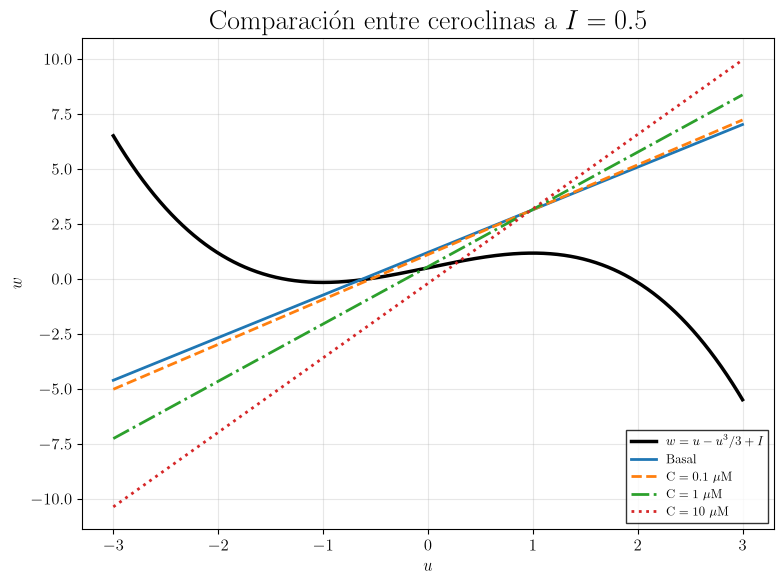

In [5]:
comparador.comparar_nulclinas(
    sistemas=sistemas,
    u_min=-3,
    u_max=3,
    titulo=rf"Comparación entre ceroclinas a $I={sistema_basal['I']}$",
    guardar=True,
    ruta=CARPETA_IMAGENES,
    nombre_archivo="FHNcomp_comparacion_nulclinas.pdf"
)

## **Comparar puntos de equilibrio**

In [6]:
resultados_equilibrios = comparador.comparar_equilibrios(
    sistemas=sistemas,
    imprimir=True
)

Sistema: Basal
a = -0.61824408
b = 0.51584921
epsilon = 0.02865784
I = 0.5
Número de equilibrios: 1
  Equilibrio 1
    u* = -0.64771829
    w* = -0.05713727
    traza = 0.56567789
    determinante = 0.02007681
    discriminante = 0.23968422
    autovalores = [0.52762672+0.j 0.03805117+0.j]
    tipo = nodo inestable
    estabilidad = inestable

Sistema: $\mathrm{C}=0.1\ \mu$M
a = -0.537867279752066
b = 0.4899174815702479
epsilon = 0.030179350743801653
I = 0.5
Número de equilibrios: 1
  Equilibrio 1
    u* = -0.52729880
    w* = 0.02157196
    traza = 0.70717059
    determinante = 0.01950495
    discriminante = 0.42207044
    autovalores = [0.67842004+0.j 0.02875055+0.j]
    tipo = nodo inestable
    estabilidad = inestable

Sistema: $\mathrm{C}=1\ \mu$M
a = -0.21012144999999996
b = 0.38385835499999993
epsilon = 0.040505229999999996
I = 0.5
Número de equilibrios: 1
  Equilibrio 1
    u* = -0.02952078
    w* = 0.47048780
    traza = 0.98358025
    determinante = 0.02497051
    discriminan

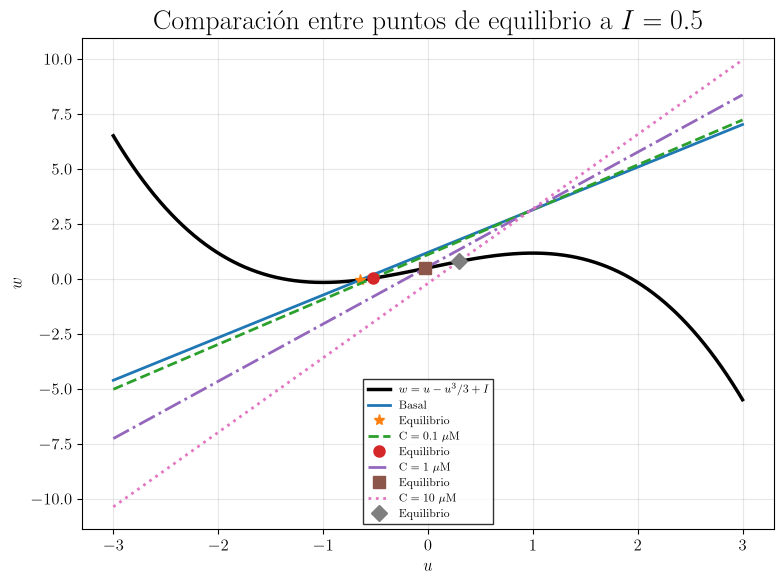

In [55]:
comparador.graficar_equilibrios(
    sistemas=sistemas,
    u_min=-3,
    u_max=3,
    titulo=rf"Comparación entre puntos de equilibrio a $I={sistema_basal["I"]}$",
    guardar=True,
    ruta=CARPETA_IMAGENES,
    nombre_archivo="FHNcomp_comparacion_equilibrios.pdf"
)

## **Comparar corrientes de Hopf**

In [8]:
resultados_hopf = comparador.comparar_hopf(
    sistemas=sistemas,
    imprimir=True
)

Sistema: Basal
a = -0.61824408
b = 0.51584921
epsilon = 0.02865784
  Candidato Hopf 1
    u_H = -0.99258092
    w_H = -0.72567105
    I_H = -0.05905929
    traza = 9.19403442e-17
    determinante = 0.02843930
    d(traza)/dI = 1.03191339
    transversalidad = True
    es Hopf = True
  Candidato Hopf 2
    u_H = 0.99258092
    w_H = 3.12266640
    I_H = 2.45605464
    traza = 9.19403442e-17
    determinante = 0.02843930
    d(traza)/dI = -1.03191339
    transversalidad = True
    es Hopf = True

Sistema: $\mathrm{C}=0.1\ \mu$M
a = -0.537867279752066
b = 0.4899174815702479
epsilon = 0.030179350743801653
  Candidato Hopf 1
    u_H = -0.99257977
    w_H = -0.92814099
    I_H = -0.26152924
    traza = -4.33680869e-17
    determinante = 0.02996074
    d(traza)/dI = 0.97966066
    transversalidad = True
    es Hopf = True
  Candidato Hopf 2
    u_H = 0.99257977
    w_H = 3.12388741
    I_H = 2.45727567
    traza = -4.33680869e-17
    determinante = 0.02996074
    d(traza)/dI = -0.97966066
   

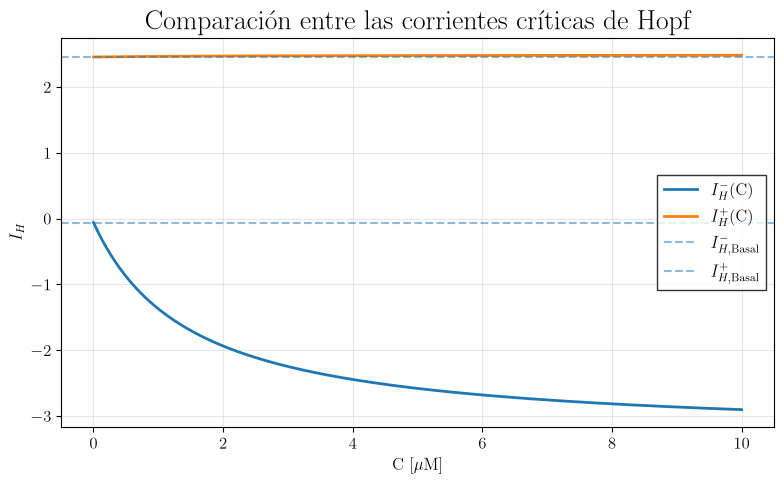

In [10]:
resultado_barrido_Hopf = comparador.barrer_hopf_Barrett_GC(
    GC_min=0.0,
    GC_max=10.0,
    num_GC=300,
    incluir_clasico=True,
    a_clasico=a0,
    b_clasico=b0,
    epsilon_clasico=epsilon0,
    guardar=True,
    titulo="Comparación entre las corrientes críticas de Hopf",
    ruta=CARPETA_IMAGENES,
    nombre_archivo="FHNcomp_umbrales_Hopf.pdf"
)

## **Comparación de regiones de estabilidad**

### **Primera etapa**

/home/fer/Documentos/TESIS/Simulaciones/Simulaciones_GitHub/FHN-comparacion/FHN_comparacion_Definicion.py:1158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


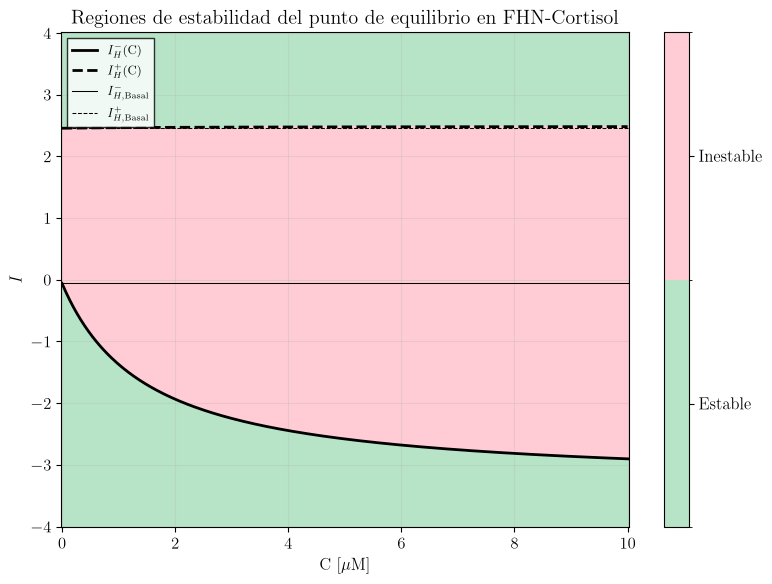

In [11]:
resultado_regimenes = comparador.barrer_regimenes_GC_I(
    GC_min=0.0,
    GC_max=10.0,
    num_GC=300,
    I_min=-4.0,
    I_max=4.0,
    num_I=300,
    incluir_hopf=True,
    incluir_clasico=True,
    a_clasico=a0,
    b_clasico=b0,
    epsilon_clasico=epsilon0,
    guardar=True,
    titulo="Regiones de estabilidad del punto de equilibrio en FHN-Cortisol",
    ruta=CARPETA_IMAGENES,
    nombre_archivo="FHNcomp_regimenes_dinamicos_Barrett.pdf"
)

Comparación de intervalos

In [12]:
intervalos_estables_GC1 = comparador.intervalos_I_por_regimen(
    resultado_regimenes=resultado_regimenes,
    GC_objetivo=1.0,
    codigo_regimen=0
)

print(intervalos_estables_GC1)

{'GC_objetivo': 1.0, 'GC_usado': np.float64(1.0033444816053512), 'codigo_regimen': 0, 'intervalos_I': [(np.float64(-4.0), np.float64(-1.3779264214046822)), (np.float64(2.4749163879598663), np.float64(4.0))]}


In [13]:
intervalos_inestables_GC1 = comparador.intervalos_I_por_regimen(
    resultado_regimenes=resultado_regimenes,
    GC_objetivo=1.0,
    codigo_regimen=1
)

print(intervalos_inestables_GC1)

{'GC_objetivo': 1.0, 'GC_usado': np.float64(1.0033444816053512), 'codigo_regimen': 1, 'intervalos_I': [(np.float64(-1.351170568561873), np.float64(2.448160535117057))]}


### **Segunda etapa**

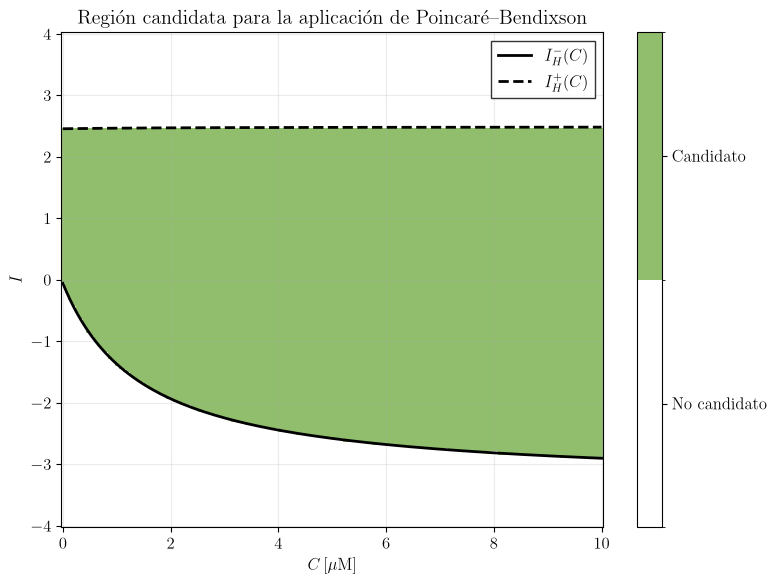

In [14]:
resultado_PB = comparador.barrer_poincare_bendixson_GC_I(
    GC_min=0.0,
    GC_max=10.0,
    num_GC=150,
    I_min=-4.0,
    I_max=4.0,
    num_I=150,
    R=5.0,
    W=20.0,
    verificar_atrapante=True,
    guardar=True,
    ruta=CARPETA_IMAGENES,
    nombre_archivo="FHNcomp_region_aplicacion_PoincareBendixson.pdf"
)

In [15]:
candidatos = resultado_PB["candidatos"]

print("Número de candidatos:", len(candidatos))

Número de candidatos: 13408


In [16]:
resultados_elipse = comparador.verificar_elipses_candidatos(
    candidatos=resultado_PB["candidatos"],
    rho_vals=[
        0.001,
        0.002,
        0.005,
        0.01,
        0.02,
        0.05,
        0.1
    ],
    num_elipse=400,
    tol=1e-10
)

In [17]:
print("Candidatos preliminares:", len(candidatos))

print(
    "Con elipse repulsora:",
    sum(r["elipse_repulsora"] for r in resultados_elipse)
)

Candidatos preliminares: 13408
Con elipse repulsora: 13408


In [18]:
matriz_PB_elipse = comparador.construir_matriz_elipse_repulsora(
    resultados_elipse=resultados_elipse,
    GC_vals=resultado_PB["GC_vals"],
    I_vals=resultado_PB["I_vals"]
)

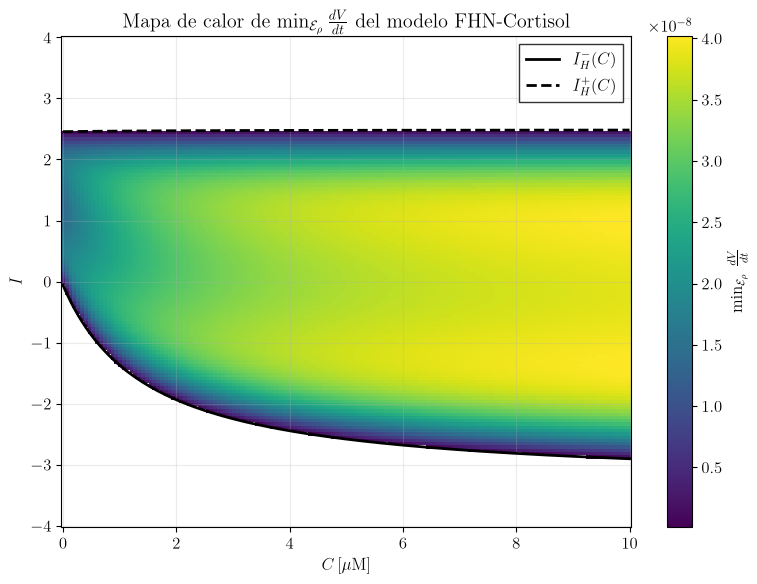

In [65]:
matriz_min_dVdt = comparador.graficar_min_dVdt_elipse(
    resultado_PB=resultado_PB,
    resultados_elipse=resultados_elipse,
    matriz_PB_elipse=matriz_PB_elipse,
    titulo=(
        r"Mapa de calor de "
        r"$\min_{\mathcal{E}_\rho}\frac{dV}{dt}$ "
        r"del modelo FHN-Cortisol"
    ),
    figsize=(8, 6),
    guardar=True,
    ruta=CARPETA_IMAGENES,
    nombre_archivo="FHNcomp_min_dVdt_elipse.pdf"
)

In [20]:
print("Forma de la matriz:", matriz_min_dVdt.shape)
print("Número de valores finitos:", np.sum(np.isfinite(matriz_min_dVdt)))
print("Número de NaN:", np.sum(~np.isfinite(matriz_min_dVdt)))

valores = matriz_min_dVdt[np.isfinite(matriz_min_dVdt)]

print("Mínimo:", np.min(valores))
print("Máximo:", np.max(valores))
print("Media:", np.mean(valores))
print("Mediana:", np.median(valores))

print("GC mínimo:", resultado_PB["GC_vals"][0])
print("GC máximo:", resultado_PB["GC_vals"][-1])

print("I mínimo:", resultado_PB["I_vals"][0])
print("I máximo:", resultado_PB["I_vals"][-1])

print("Candidatos:", len(candidatos))
print("Elipses repulsoras:", len(resultados_elipse))

print(
    "Porcentaje:",
    100 * len(resultados_elipse) / len(candidatos)
)
print(resultado_PB.keys())
print("Total de puntos evaluados:", ...)

Forma de la matriz: (150, 150)
Número de valores finitos: 13408
Número de NaN: 9092
Mínimo: 1.0942023961270954e-10
Máximo: 4.021269945281682e-08
Media: 2.9715632167443565e-08
Mediana: 3.3641037998404424e-08
GC mínimo: 0.0
GC máximo: 10.0
I mínimo: -4.0
I máximo: 4.0
Candidatos: 13408
Elipses repulsoras: 13408
Porcentaje: 100.0
dict_keys(['GC_vals', 'I_vals', 'matriz_PB', 'traza', 'determinante', 'num_equilibrios', 'candidatos', 'R', 'W', 'verificar_atrapante', 'I_H_menos', 'I_H_mas'])
Total de puntos evaluados: Ellipsis


Valor utilizado para FHN-Basal: C = 0.000000 μM


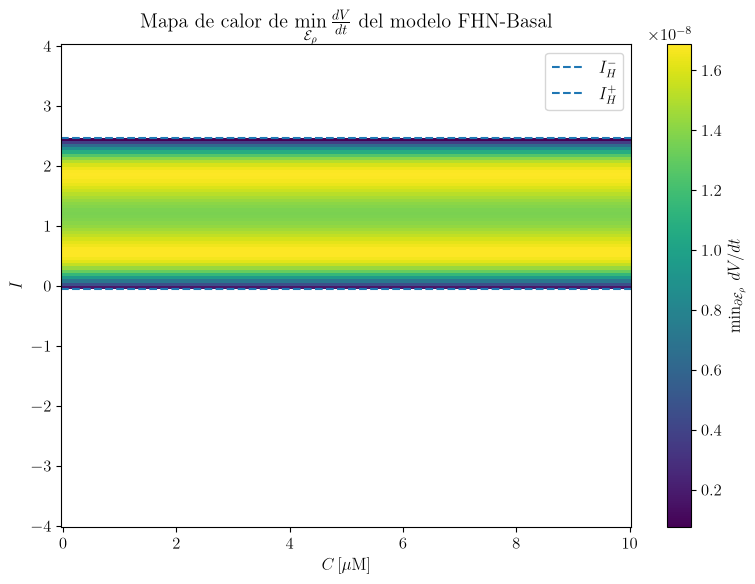

In [21]:
matriz_basal = comparador.graficar_min_dVdt_elipse_basal_2D(
    resultado_PB=resultado_PB,
    resultados_elipse=resultados_elipse,
    figsize=(8, 6),
    titulo=(r"Mapa de calor de $\min\limits_{\mathcal{E}_\rho} \frac{dV}{dt}$ del modelo FHN-Basal"),
    guardar=True,
    ruta=CARPETA_IMAGENES,
    nombre_archivo="FHNcomp_min_dVdt_elipse_basal.pdf"
)

In [22]:
valores_basal = matriz_basal[np.isfinite(matriz_basal)]

print("Forma:", matriz_basal.shape)
print("Mínimo:", np.min(valores_basal))
print("Máximo:", np.max(valores_basal))
print("Media:", np.mean(valores_basal))
print("Mediana:", np.median(valores_basal))

Forma: (150, 150)
Mínimo: 7.419111803240259e-10
Máximo: 1.6869757410346336e-08
Media: 1.3374385266958012e-08
Mediana: 1.4616973494808026e-08


## **Analizar comportamiento cerca de umbrales Hopf**

### **Simulación 1**

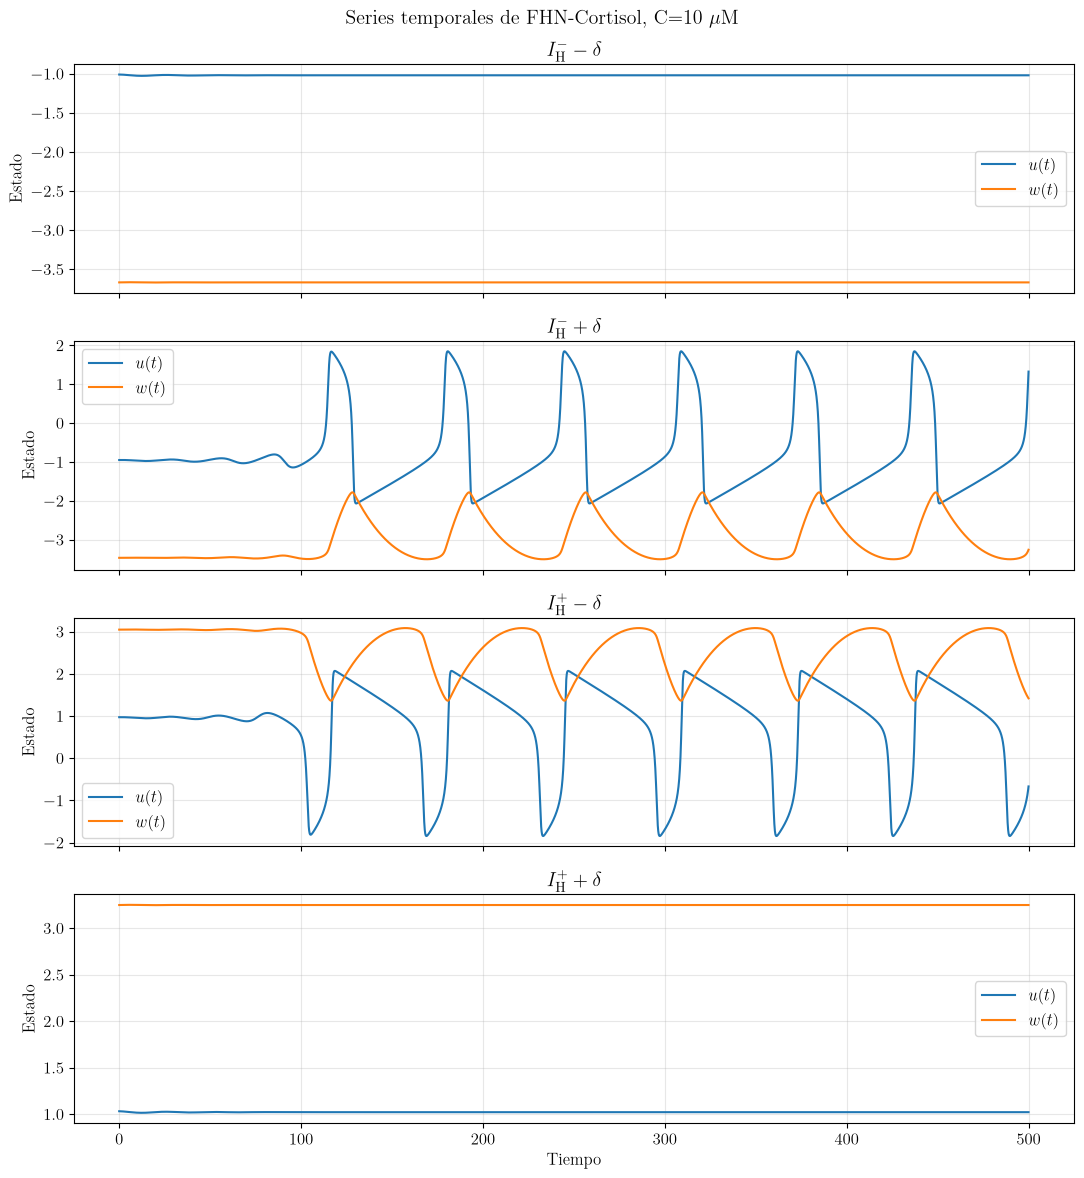

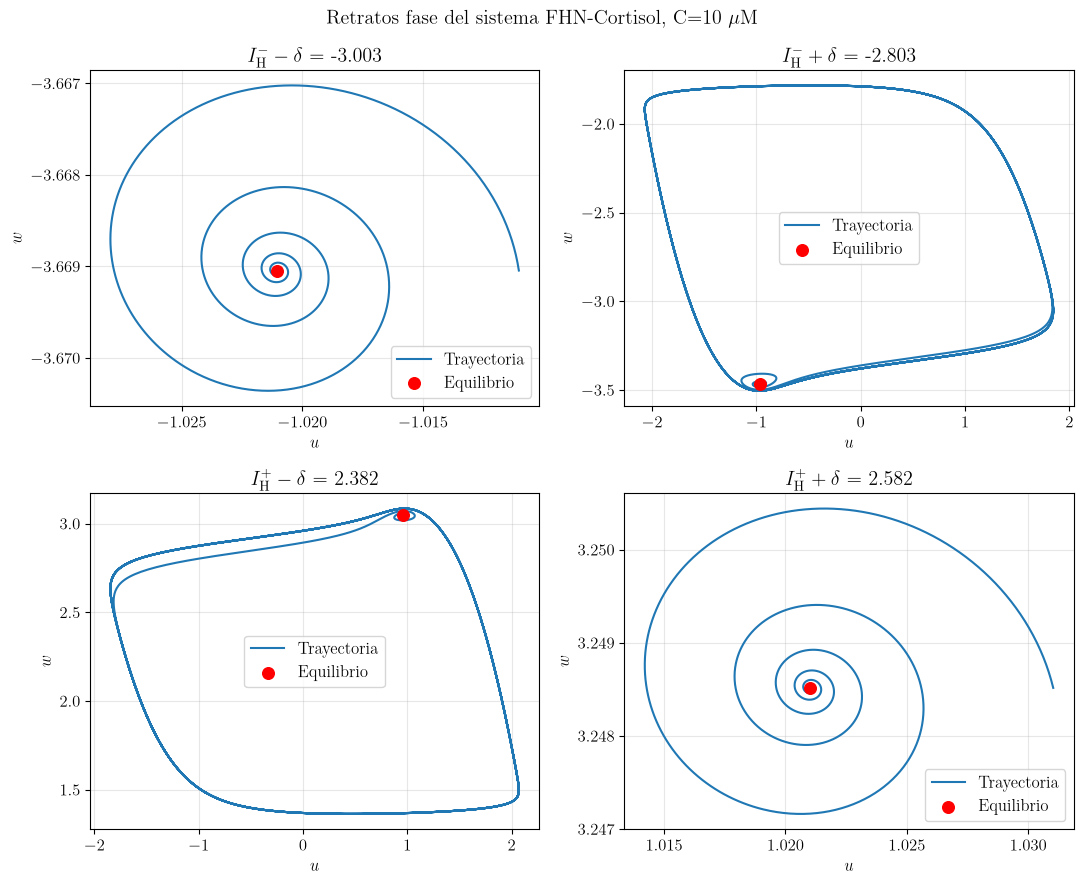

In [23]:
resultado = comparador.analizar_hopf_concentracion(
    C=10.0,
    delta=0.1,
    t_final=500.0,
    num_tiempos=10000,
    perturbacion_inicial=0.01,
    mostrar_graficas=True,
    guardar=False,
    ruta = CARPETA_IMAGENES,
    nombre_archivo_1= "FHNcomp_Hopf_concentracion_series_temporales_FHN_C_10.pdf",
    nombre_archivo_2= "FHNcomp_Hopf_concentracion_retratos_fase_FHN_C_10.pdf"
)

### **Simulación 2**

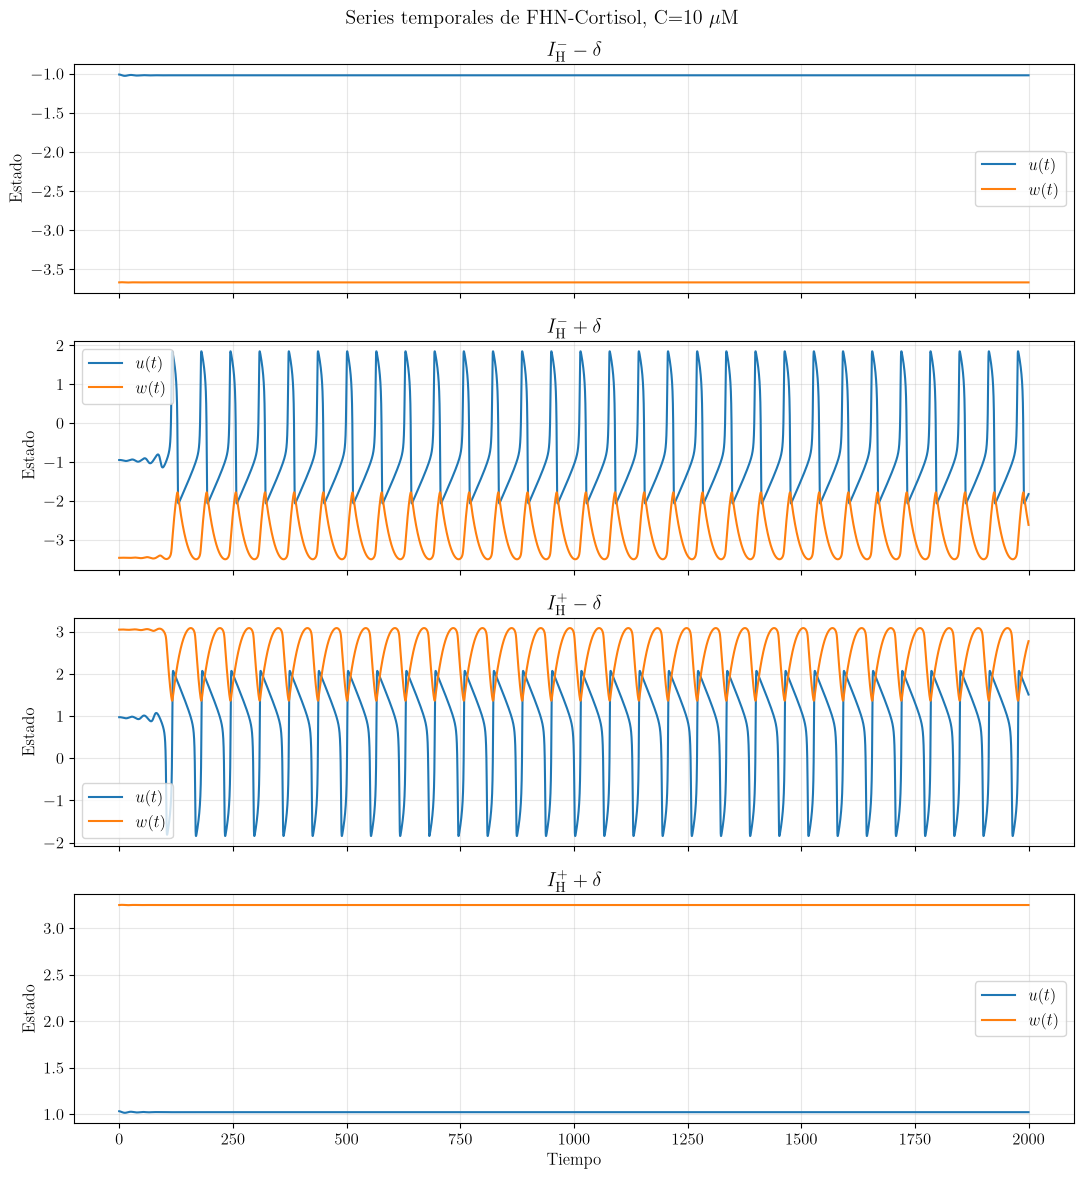

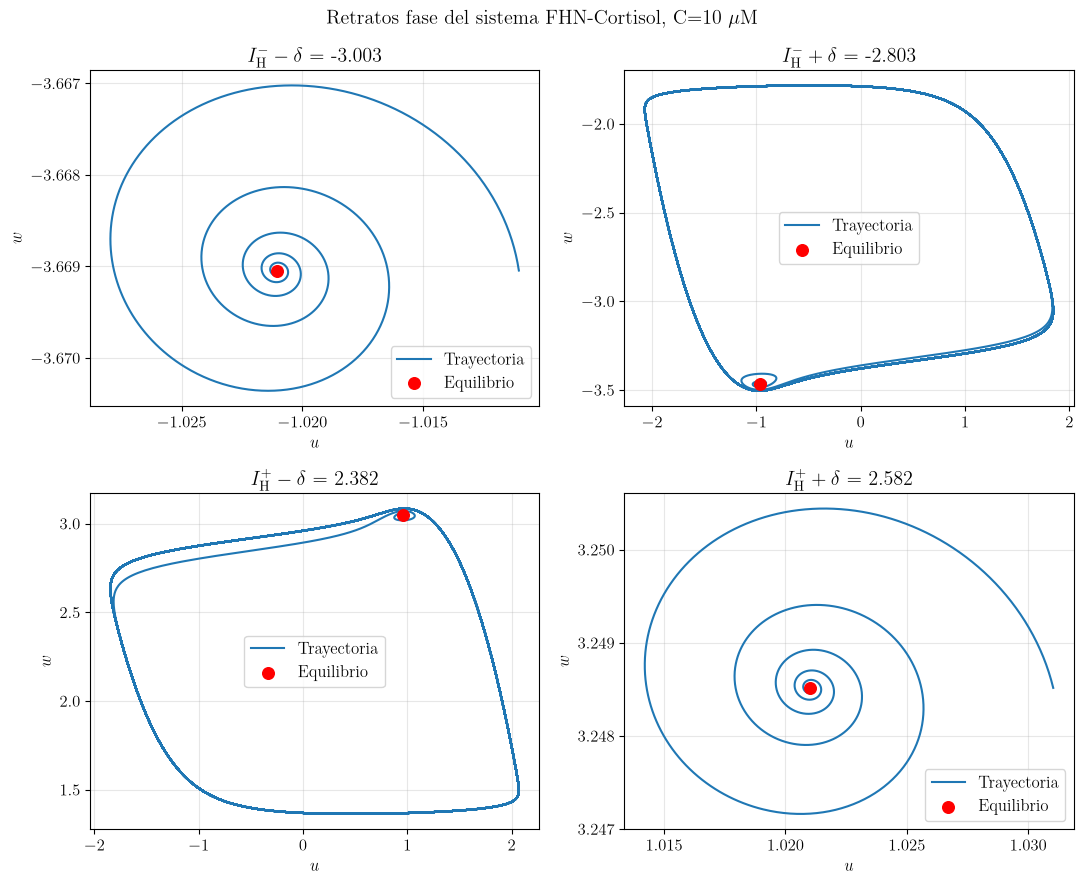

In [24]:
resultado_largo = comparador.analizar_hopf_concentracion(
    C=10.0,
    delta=0.1,
    t_final=2000.0,
    num_tiempos=40000,
    perturbacion_inicial=0.01,
    rtol=1e-9,
    atol=1e-11,
    max_step=0.1,
    mostrar_graficas=True,
    guardar=True,
    ruta=CARPETA_IMAGENES,
    nombre_archivo_1="FHNcomp_Hopf_concentracion_series_temporales_FHN_C_10.pdf",
    nombre_archivo_2="FHNcomp_Hopf_concentracion_retratos_fase_FHN_C_10.pdf"
)

### **Análisis de resultados**

In [25]:
resultado["parametros"]
resultado["puntos_hopf"]

import pandas as pd

tabla = pd.DataFrame(resultado["resumen"])
display(tabla)

,caso,I,numero_equilibrios,u_equilibrio,w_equilibrio,traza,determinante,autovalores,tipo_equilibrio,estabilidad,integracion_exitosa
0,$I_\mathrm{H}^- - \delta$,-3.002824,1,-1.021031,-3.669045,-0.059190,0.057233,"[(-0.029595211005687756+0.23739734796981604j),...",foco estable,estable,True
1,$I_\mathrm{H}^- + \delta$,-2.802824,1,-0.961695,-3.468042,0.058457,0.055270,"[(0.02922838013458493+0.23327243351203186j), (...",foco inestable,inestable,True
2,$I_\mathrm{H}^+ - \delta$,2.382294,1,0.961695,3.047512,0.058457,0.055270,"[(0.029228380134584703+0.2332724335120319j), (...",foco inestable,inestable,True
3,$I_\mathrm{H}^+ + \delta$,2.582294,1,1.021031,3.248515,-0.059190,0.057233,"[(-0.029595211005687756+0.23739734796981604j),...",foco estable,estable,True


In [26]:
import numpy as np
import pandas as pd

filas = []

for nombre, caso in resultado_largo["resultados"].items():

    sol = caso["solucion"]

    if sol is None or not sol.success:
        filas.append({
            "caso": nombre,
            "integracion_exitosa": False
        })
        continue

    t = sol.t
    u = sol.y[0]
    w = sol.y[1]

    # Dos ventanas de igual duración al final de la simulación.
    # Cada una comprende el 10 % del tiempo total.
    inicio = t[0]
    fin = t[-1]
    duracion = fin - inicio

    mascara_1 = (
        (t >= fin - 0.20 * duracion) &
        (t <  fin - 0.10 * duracion)
    )

    mascara_2 = (
        (t >= fin - 0.10 * duracion) &
        (t <= fin)
    )

    fila = {
        "caso": nombre,
        "I": caso["I"],
        "integracion_exitosa": sol.success,
        "puntos_ventana_1": int(np.sum(mascara_1)),
        "puntos_ventana_2": int(np.sum(mascara_2))
    }

    for variable, valores in [("u", u), ("w", w)]:

        x1 = valores[mascara_1]
        x2 = valores[mascara_2]

        if len(x1) < 10 or len(x2) < 10:
            fila[f"{variable}_amplitud_1"] = np.nan
            fila[f"{variable}_amplitud_2"] = np.nan
            fila[f"{variable}_cambio_amplitud_pct"] = np.nan
            fila[f"{variable}_media_1"] = np.nan
            fila[f"{variable}_media_2"] = np.nan
            fila[f"{variable}_cambio_media"] = np.nan
            continue

        amplitud_1 = np.max(x1) - np.min(x1)
        amplitud_2 = np.max(x2) - np.min(x2)

        fila[f"{variable}_amplitud_1"] = amplitud_1
        fila[f"{variable}_amplitud_2"] = amplitud_2

        # Cambio relativo de amplitud, expresado en porcentaje.
        escala = max(abs(amplitud_1), 1e-12)

        fila[f"{variable}_cambio_amplitud_pct"] = (
            100 * (amplitud_2 - amplitud_1) / escala
        )

        media_1 = np.mean(x1)
        media_2 = np.mean(x2)

        fila[f"{variable}_media_1"] = media_1
        fila[f"{variable}_media_2"] = media_2
        fila[f"{variable}_cambio_media"] = media_2 - media_1

    filas.append(fila)

tabla_ventanas = pd.DataFrame(filas)

display(tabla_ventanas.round(6))


,caso,I,integracion_exitosa,puntos_ventana_1,puntos_ventana_2,u_amplitud_1,u_amplitud_2,u_cambio_amplitud_pct,u_media_1,u_media_2,u_cambio_media,w_amplitud_1,w_amplitud_2,w_cambio_amplitud_pct,w_media_1,w_media_2,w_cambio_media
0,$I_\mathrm{H}^- - \delta$,-3.002824,True,4000,4000,0.000000,0.000000,0.000000,-1.021031,-1.021031,0.000000,0.000000,0.000000,0.000000,-3.669045,-3.669045,0.000000
1,$I_\mathrm{H}^- + \delta$,-2.802824,True,4000,4000,3.914760,3.914753,-0.000155,-0.788330,-0.839033,-0.050703,1.721792,1.721792,-0.000028,-2.869485,-2.886986,-0.017501
2,$I_\mathrm{H}^+ - \delta$,2.382294,True,4000,4000,3.914799,3.914801,0.000059,0.834788,0.827056,-0.007731,1.721771,1.721769,-0.000124,2.477122,2.492171,0.015049
3,$I_\mathrm{H}^+ + \delta$,2.582294,True,4000,4000,0.000000,0.000000,0.000000,1.021031,1.021031,0.000000,0.000000,0.000000,0.000000,3.248515,3.248515,0.000000


In [27]:

from scipy.signal import find_peaks

filas_periodo = []

for nombre, caso in resultado_largo["resultados"].items():

    sol = caso["solucion"]

    if sol is None or not sol.success:
        filas_periodo.append({
            "caso": nombre,
            "numero_maximos": 0,
            "periodo_medio": np.nan,
            "desviacion_periodo": np.nan,
            "amplitud_u": np.nan
        })
        continue

    t = sol.t
    u = sol.y[0]

    # Analizar solamente el último 40 % de la trayectoria.
    mascara = t >= t[0] + 0.60 * (t[-1] - t[0])

    tt = t[mascara]
    uu = u[mascara]

    if len(tt) < 10:
        continue

    # Separación mínima aproximada entre máximos:
    # se usa como filtro para evitar contar el mismo pico
    # varias veces debido a pequeñas fluctuaciones.
    dt = np.median(np.diff(tt))
    separacion_minima = max(
        1,
        int(0.5 / dt)
    )

    indices, _ = find_peaks(
        uu,
        distance=separacion_minima
    )

    tiempos_maximos = tt[indices]
    valores_maximos = uu[indices]

    periodos = np.diff(tiempos_maximos)

    if len(periodos) >= 2:
        periodo_medio = np.mean(periodos)
        desviacion_periodo = np.std(
            periodos, ddof=1
        )
    else:
        periodo_medio = np.nan
        desviacion_periodo = np.nan

    filas_periodo.append({
        "caso": nombre,
        "numero_maximos": len(indices),
        "periodo_medio": periodo_medio,
        "desviacion_periodo": desviacion_periodo,
        "amplitud_u": (
            np.max(uu) - np.min(uu)
            if len(uu) else np.nan
        ),
        "tiempos_maximos": tiempos_maximos.tolist()
    })

tabla_periodos = pd.DataFrame(filas_periodo)

display(
    tabla_periodos.drop(
        columns=["tiempos_maximos"],
        errors="ignore"
    ).round(6)
)


,caso,numero_maximos,periodo_medio,desviacion_periodo,amplitud_u
0,$I_\mathrm{H}^- - \delta$,0,NaN,NaN,0.000000
1,$I_\mathrm{H}^- + \delta$,13,64.155771,0.014434,3.914771
2,$I_\mathrm{H}^+ - \delta$,13,64.151604,0.000000,3.914801
3,$I_\mathrm{H}^+ + \delta$,0,NaN,NaN,0.000000


In [30]:

for nombre in [
    r"$I_\mathrm{H}^- + \delta$",
    r"$I_\mathrm{H}^+ - \delta$"
]:
    sol = resultado_largo["resultados"][nombre]["solucion"]

    t = sol.t
    u = sol.y[0]

    mascara = t >= t[0] + 0.60 * (t[-1] - t[0])
    tt, uu = t[mascara], u[mascara]

    from scipy.signal import find_peaks

    dt = np.median(np.diff(tt))
    indices, _ = find_peaks(
        uu,
        distance=max(1, int(0.5 / dt))
    )

    tiempos = tt[indices]
    periodos = np.diff(tiempos)

    print(f"\n{nombre}")
    print("Tiempos de máximos:")
    print([f"{x:.8f}" for x in tiempos])
    print("Períodos sucesivos:")
    print([f"{x:.8f}" for x in periodos])
    print(f"Media: {np.mean(periodos):.8f}")
    print(f"Desviación estándar: {np.std(periodos, ddof=1):.8f}")



$I_\mathrm{H}^- + \delta$
Tiempos de máximos:
['1207.08017700', '1271.23178079', '1335.38338458', '1399.53498837', '1463.68659216', '1527.83819595', '1591.98979974', '1656.14140354', '1720.29300733', '1784.44461112', '1848.59621491', '1912.74781870', '1976.94942374']
Períodos sucesivos:
['64.15160379', '64.15160379', '64.15160379', '64.15160379', '64.15160379', '64.15160379', '64.15160379', '64.15160379', '64.15160379', '64.15160379', '64.15160379', '64.20160504']
Media: 64.15577056
Desviación estándar: 0.01443412

$I_\mathrm{H}^+ - \delta$
Tiempos de máximos:
['1209.18022951', '1273.33183330', '1337.48343709', '1401.63504088', '1465.78664467', '1529.93824846', '1594.08985225', '1658.24145604', '1722.39305983', '1786.54466362', '1850.69626741', '1914.84787120', '1978.99947499']
Períodos sucesivos:
['64.15160379', '64.15160379', '64.15160379', '64.15160379', '64.15160379', '64.15160379', '64.15160379', '64.15160379', '64.15160379', '64.15160379', '64.15160379', '64.15160379']
Media: 64

In [33]:
# Para extraer la trayectoria de uno de los cuatro casos

solucion = resultado["resultados"][r"$I_\mathrm{H}^- - \delta$"]["solucion"]

t = solucion.t
u = solucion.y[0]
w = solucion.y[1]

## **Gráfica de $\min\limits_\mathcal{E} \frac{dV}{dt}$**

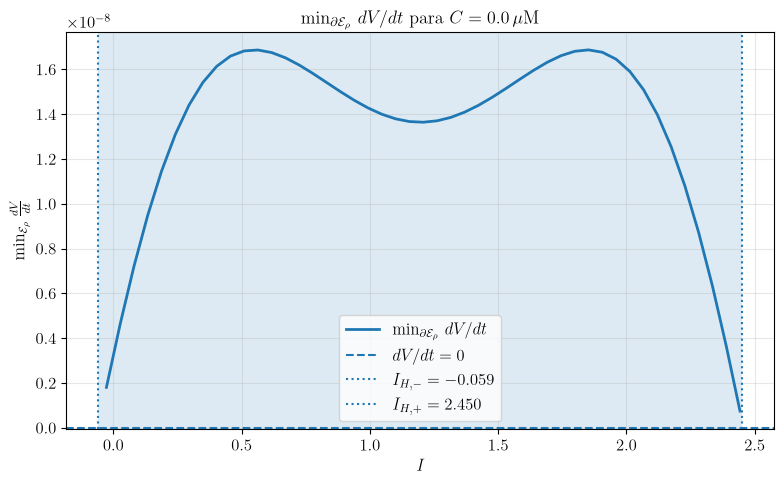

In [66]:
I_vals_1D, min_dVdt_1D = comparador.graficar_min_dVdt_1D(
    resultados_elipse=resultados_elipse,
    GC_fijo=0.0,
    I_H_menos=-0.059,
    I_H_mas=2.45,
    figsize=(8, 5),
    guardar=True,
    ruta=CARPETA_IMAGENES,
    nombre_archivo="FHNcomp_min_dVdt_vs_I_basal.pdf"
)

In [39]:
print("Número de puntos:", len(I_vals_1D))
print("I mínimo:", np.min(I_vals_1D))
print("I máximo:", np.max(I_vals_1D))

print("min(dV/dt):", np.min(min_dVdt_1D))
print("max(dV/dt):", np.max(min_dVdt_1D))

idx_min = np.argmin(min_dVdt_1D)
idx_max = np.argmax(min_dVdt_1D)

print(
    "Mínimo en I =",
    I_vals_1D[idx_min]
)

print(
    "Máximo en I =",
    I_vals_1D[idx_max]
)

for I_objetivo in [-0.059, 2.45]:
    idx = np.argmin(np.abs(I_vals_1D - I_objetivo))

    print(
        f"I ≈ {I_vals_1D[idx]:.6f}, "
        f"min(dV/dt) ≈ {min_dVdt_1D[idx]:.6e}"
    )

Número de puntos: 47
I mínimo: -0.02684563758389258
I máximo: 2.4429530201342278
min(dV/dt): 7.419111803240259e-10
max(dV/dt): 1.6869757410346336e-08
Mínimo en I = 2.4429530201342278
Máximo en I = 1.8523489932885902
I ≈ -0.026846, min(dV/dt) ≈ 1.803341e-09
I ≈ 2.442953, min(dV/dt) ≈ 7.419112e-10


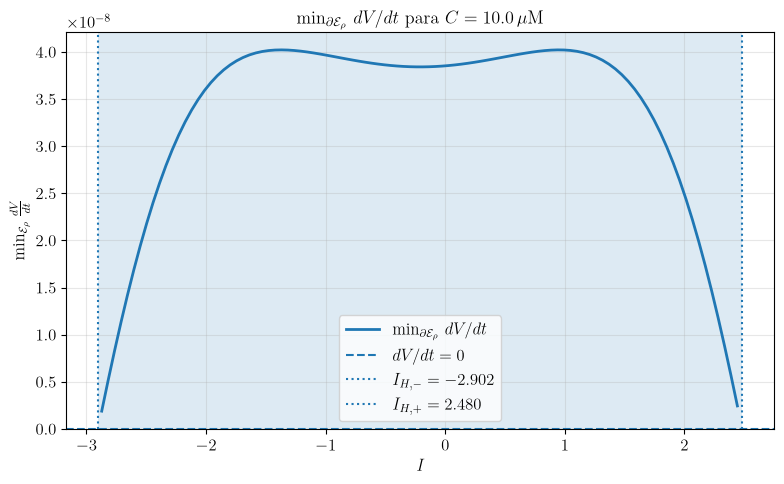

In [67]:
I_vals_1D, min_dVdt_1D = comparador.graficar_min_dVdt_1D(
    resultados_elipse=resultados_elipse,
    GC_fijo=10.0,
    I_H_menos=-2.902,
    I_H_mas=2.48,
    figsize=(8, 5),
    guardar=True,
    ruta=CARPETA_IMAGENES,
    nombre_archivo="FHNcomp_min_dVdt_vs_I_C10.pdf"
)

In [45]:
print("Número de puntos:", len(I_vals_1D))
print("I mínimo:", np.min(I_vals_1D))
print("I máximo:", np.max(I_vals_1D))

print("min(dV/dt):", np.min(min_dVdt_1D))
print("max(dV/dt):", np.max(min_dVdt_1D))

idx_min = np.argmin(min_dVdt_1D)
idx_max = np.argmax(min_dVdt_1D)

print(
    "Mínimo en I =",
    I_vals_1D[idx_min]
)

print(
    "Máximo en I =",
    I_vals_1D[idx_max]
)

for I_objetivo in [-2.902, 2.48]:
    idx = np.argmin(np.abs(I_vals_1D - I_objetivo))

    print(
        f"I ≈ {I_vals_1D[idx]:.6f}, "
        f"min(dV/dt) ≈ {min_dVdt_1D[idx]:.6e}"
    )

Número de puntos: 100
I mínimo: -2.87248322147651
I máximo: 2.4429530201342278
min(dV/dt): 1.885576970826718e-09
max(dV/dt): 4.021269945281682e-08
Mínimo en I = -2.87248322147651
Máximo en I = -1.3691275167785237
I ≈ -2.872483, min(dV/dt) ≈ 1.885577e-09
I ≈ 2.442953, min(dV/dt) ≈ 2.438995e-09


In [46]:
I_H_menos_basal = -0.059
I_H_menos_C10 = -2.902

I_H_mas_basal = 2.45
I_H_mas_C10 = 2.48

print(
    "Desplazamiento I_H^- =",
    I_H_menos_C10 - I_H_menos_basal
)

print(
    "Desplazamiento I_H^+ =",
    I_H_mas_C10 - I_H_mas_basal
)

print(
    "Ancho basal =",
    I_H_mas_basal - I_H_menos_basal
)

print(
    "Ancho C=10 =",
    I_H_mas_C10 - I_H_menos_C10
)

print(
    "Factor de expansión =",
    (I_H_mas_C10 - I_H_menos_C10) /
    (I_H_mas_basal - I_H_menos_basal)
)

Desplazamiento I_H^- = -2.843
Desplazamiento I_H^+ = 0.029999999999999805
Ancho basal = 2.5090000000000003
Ancho C=10 = 5.382
Factor de expansión = 2.1450777202072535
